# B5 – Integrasi Rangkaian Praproses SIMUTEH

**SIMUTEH · NIM 2230511115 · SEED 1115**

Notebook ini memakai modul `src/praproses.py` untuk menggabungkan resize, koreksi gamma, CLAHE kanal V, penapisan, dan penajaman opsional. Parameter final disimpan sebagai JSON agar dapat digunakan kembali mulai Pertemuan 5.

**Lokasi Google Drive:** simpan folder repository ini di `My Drive/Colab Notebooks/simuteh-2230511115/`. Buka notebook dari subfolder `notebook/`. Sel persiapan akan memasang Google Drive di Colab.

> **Catatan Google Colab:** Jalankan sel persiapan terlebih dahulu dan izinkan akses Google Drive. Pastikan folder `simuteh-2230511115` lengkap berada di `Drive Saya/Colab Notebooks/`. Jika sebelumnya pernah menjalankan versi lama, pilih **Runtime → Restart session** lalu jalankan notebook dari atas.

## 5.1 Persiapan dan parameter awal

In [1]:
from pathlib import Path
import sys, subprocess, json, time, platform, importlib.metadata
import importlib, ast, os

# Pustaka utama yang dipakai pada seluruh notebook. Google Colab umumnya sudah
# menyediakannya; requirements.txt tetap disediakan untuk lingkungan lain.
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skimage
from IPython.display import display
from time import perf_counter

# 1) Pasang Google Drive (khusus Google Colab).
try:
    from google.colab import drive
    IN_COLAB = True
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except ImportError:
    IN_COLAB = False

# 2) Temukan folder repository. Path yang mengandung spasi aman karena
#    seluruh operasi memakai pathlib, bukan pemisahan string shell.
DRIVE_NOTEBOOKS = Path("/content/drive/MyDrive/Colab Notebooks")
_kandidat = [
    DRIVE_NOTEBOOKS / "simuteh-2230511115",
    DRIVE_NOTEBOOKS / "simuteh-2230511115" / "simuteh-2230511115",  # jika folder ter-ekstrak ganda
    Path.cwd(),
    *Path.cwd().parents,
    Path("/content/simuteh-2230511115"),
]

# Tambahkan kandidat folder satu tingkat di bawah Colab Notebooks,
# berguna bila pengguna mengunggah folder dengan nama tambahan.
if DRIVE_NOTEBOOKS.exists():
    _kandidat.extend(sorted(DRIVE_NOTEBOOKS.glob("*/simuteh-2230511115")))
    _kandidat.extend(sorted(DRIVE_NOTEBOOKS.glob("*")))

def _folder_repository(p):
    return (p.is_dir()
            and (p / "src" / "utils_cv.py").is_file()
            and (p / "src" / "buat_dataset_sintetis.py").is_file())

ROOT = next((p.resolve() for p in _kandidat if _folder_repository(p)), None)
if ROOT is None:
    raise FileNotFoundError(
        "Folder repository SIMUTEH belum ditemukan. Pastikan folder "
        "simuteh-2230511115 (yang berisi src/, notebook/, data/, dan hasil/) "
        "sudah diunggah ke Google Drive > Drive Saya > Colab Notebooks. "
        "Jangan hanya mengunggah file .ipynb secara terpisah."
    )

SRC = ROOT / "src"
DATA = ROOT / "data" / "sintetis"
CITRA = DATA / "citra"
BERSIH = DATA / "bersih"
MASK_DAUN = DATA / "mask_daun"
MASK_BERCAK = DATA / "mask_bercak"
HASIL = ROOT / "hasil"
HASIL.mkdir(parents=True, exist_ok=True)
for _folder in (CITRA, BERSIH, MASK_DAUN, MASK_BERCAK):
    _folder.mkdir(parents=True, exist_ok=True)

# 3) Hindari modul lama yang mungkin masih tersimpan di memori Colab
#    setelah pengguna mengganti file src atau berpindah notebook.
for _nama_modul in ("buat_dataset_sintetis", "utils_cv", "praproses"):
    sys.modules.pop(_nama_modul, None)
importlib.invalidate_caches()
_src_text = str(SRC.resolve())
sys.path[:] = [_src_text] + [p for p in sys.path if str(p) != _src_text]

# 4) Ambil SEED dari file sumber tanpa mengimpor modul generator.
#    Ini menghindari ImportError bila kernel Colab menyimpan modul lama.
SCRIPT_DATASET = SRC / "buat_dataset_sintetis.py"
def _baca_konstanta_seed(path):
    tree = ast.parse(path.read_text(encoding="utf-8"), filename=str(path))
    for node in tree.body:
        if isinstance(node, ast.Assign):
            if any(isinstance(target, ast.Name) and target.id == "SEED" for target in node.targets):
                return ast.literal_eval(node.value)
        elif isinstance(node, ast.AnnAssign) and isinstance(node.target, ast.Name) and node.target.id == "SEED":
            return ast.literal_eval(node.value)
    raise ValueError(
        f"Konstanta SEED tidak ditemukan di {path}. Ganti file src/buat_dataset_sintetis.py "
        "dengan versi repository SIMUTEH yang terbaru."
    )

NIM = "2230511115"
SEED = _baca_konstanta_seed(SCRIPT_DATASET)
if str(SEED) != NIM[-4:]:
    raise ValueError(
        f"SEED pada src/buat_dataset_sintetis.py adalah {SEED}, sedangkan "
        f"empat digit terakhir NIM adalah {NIM[-4:]}. Periksa file sumber sebelum membuat dataset."
    )

# 5) Impor fungsi bantu dari lokasi src yang sudah dipastikan benar.
from utils_cv import baca, tampil, kontras_bercak, statistik

# 6) Buat ulang dataset hanya bila belum lengkap / label belum valid.
import pandas as pd
label_path = DATA / "label.csv"
subfolder_dataset = (CITRA, BERSIH, MASK_DAUN, MASK_BERCAK)
dataset_lengkap = label_path.is_file()
if dataset_lengkap:
    try:
        _cek_label = pd.read_csv(label_path)
        dataset_lengkap = (
            len(_cek_label) == 60
            and _cek_label["nama_file"].nunique() == 60
            and all(sum(1 for _ in folder.glob("teh_*.png")) == 60 for folder in subfolder_dataset)
        )
    except Exception:
        dataset_lengkap = False

if not dataset_lengkap:
    print("Dataset belum lengkap. Membuat 60 citra sintetis menggunakan SEED", SEED)
    subprocess.run([sys.executable, str(SCRIPT_DATASET)], cwd=str(ROOT), check=True)

label = pd.read_csv(label_path)
assert len(label) == 60 and label["nama_file"].nunique() == 60, "Dataset harus berisi 60 citra unik."
for _folder in subfolder_dataset:
    _jumlah = sum(1 for _ in _folder.glob("teh_*.png"))
    assert _jumlah == 60, f"Folder {_folder.name} harus berisi 60 gambar, ditemukan {_jumlah}."

KONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]

print("Repository:", ROOT)
print("SEED:", SEED, "| Jumlah citra:", len(label), "| Ukuran target: 640 x 480")

from praproses import PARAM_BAWAAN, praproses, simpan_param

# Parameter awal mengikuti temuan B2–B4. Sesuaikan bila hasil pengujian Anda berbeda.
KANAL_NAMA = "R"
KANAL_INDEX = {"B": 0, "G": 1, "R": 2}.get(KANAL_NAMA)
if KANAL_INDEX is None:
    raise ValueError("KANAL_NAMA harus B, G, atau R.")
PARAM_FINAL = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "rerata",
    "kernel": 5,
    "sigma": 1.0,
    "tajam_k": 0.0,
}
param_path = simpan_param(PARAM_FINAL, HASIL / "param_praproses.json")
print("Parameter disimpan di:", param_path)
display(pd.DataFrame([PARAM_FINAL]))


Mounted at /content/drive
Repository: /content/drive/MyDrive/Colab Notebooks/simuteh-2230511115
SEED: 1115 | Jumlah citra: 60 | Ukuran target: 640 x 480
Parameter disimpan di: /content/drive/MyDrive/Colab Notebooks/simuteh-2230511115/hasil/param_praproses.json


,lebar,gamma,clahe_clip,clahe_tile,penapis,kernel,sigma,tajam_k
0,640,1.0,2.0,8,rerata,5,1.0,0.0


## 5.2 Uji fungsi modul dan visualisasi alur

Masukan : (480, 640, 3) uint8 
Keluaran: (480, 640, 3) uint8


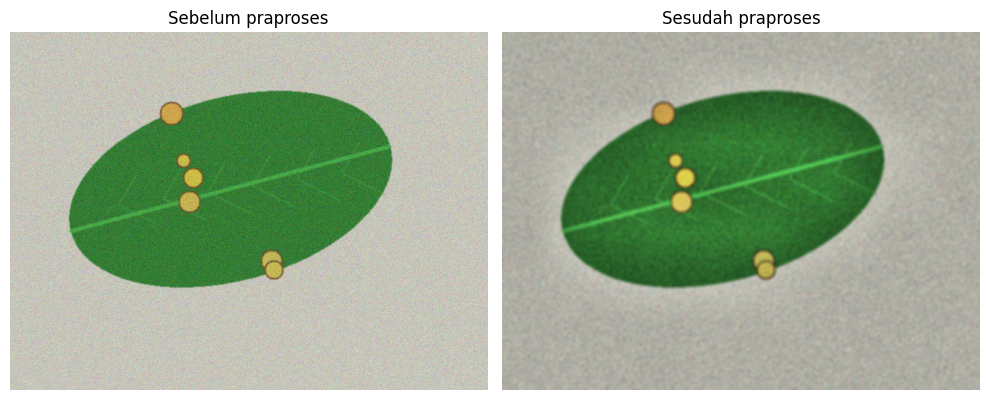

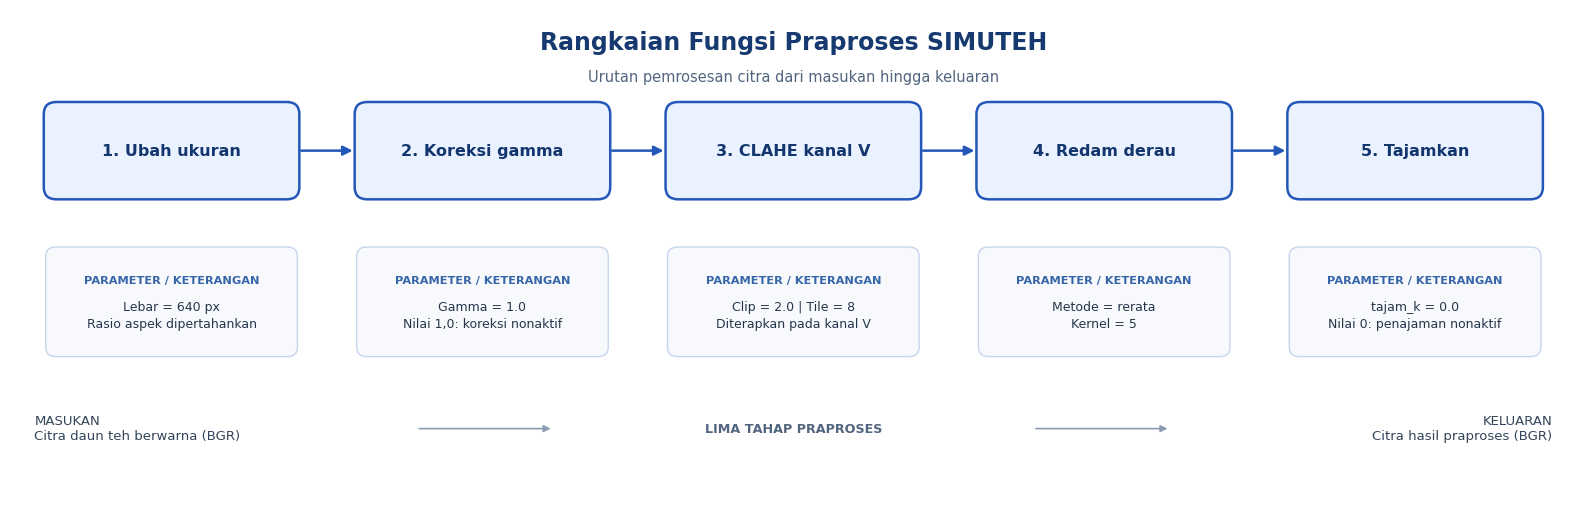

Diagram alur tersimpan di: /content/drive/MyDrive/Colab Notebooks/simuteh-2230511115/hasil/b5_diagram_praproses.png


In [2]:
# Uji fungsi modul praproses pada satu citra contoh
from matplotlib.patches import FancyBboxPatch

nama = "teh_041.png"
contoh = baca(CITRA / nama)
hasil_contoh = praproses(contoh, PARAM_FINAL)

print(
    "Masukan :", contoh.shape, contoh.dtype,
    "\nKeluaran:", hasil_contoh.shape, hasil_contoh.dtype
)

tampil(
    [contoh, hasil_contoh],
    ["Sebelum praproses", "Sesudah praproses"],
    baris=1,
    ukuran=(10, 4)
)

cv2.imwrite(str(HASIL / "b5_contoh_sebelum.png"), contoh)
cv2.imwrite(str(HASIL / "b5_contoh_sesudah.png"), hasil_contoh)

# Diagram alur lima tahap. Posisi panah dibuat di ruang antar-kotak
# agar tidak menyentuh/menimpa teks maupun kotak tahap berikutnya.
tahap = [
    ("1. Ubah ukuran",
     f"Lebar = {PARAM_FINAL['lebar']} px\nRasio aspek dipertahankan"),
    ("2. Koreksi gamma",
     f"Gamma = {PARAM_FINAL['gamma']}\nNilai 1,0: koreksi nonaktif"),
    ("3. CLAHE kanal V",
     f"Clip = {PARAM_FINAL['clahe_clip']} | Tile = {PARAM_FINAL['clahe_tile']}\nDiterapkan pada kanal V"),
    ("4. Redam derau",
     f"Metode = {PARAM_FINAL['penapis']}\nKernel = {PARAM_FINAL['kernel']}"),
    ("5. Tajamkan",
     f"tajam_k = {PARAM_FINAL['tajam_k']}\nNilai 0: penajaman nonaktif"),
]

fig, ax = plt.subplots(figsize=(16, 5.2))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
ax.set_xlim(0, 16)
ax.set_ylim(0, 5.2)
ax.axis("off")

# Judul diagram
ax.text(
    8, 4.85, "Rangkaian Fungsi Praproses SIMUTEH",
    ha="center", va="center", fontsize=17, fontweight="bold",
    color="#163A70"
)
ax.text(
    8, 4.48, "Urutan pemrosesan citra dari masukan hingga keluaran",
    ha="center", va="center", fontsize=10.5, color="#52657F"
)

# Lima kotak proses
pusat_x = np.linspace(1.65, 14.35, 5)
lebar_kotak = 2.45
tinggi_kotak = 0.88
y_kotak = 3.25

for i, ((judul, detail), cx) in enumerate(zip(tahap, pusat_x)):
    x0 = cx - lebar_kotak / 2

    # Kotak tahap
    kotak = FancyBboxPatch(
        (x0, y_kotak), lebar_kotak, tinggi_kotak,
        boxstyle="round,pad=0.08,rounding_size=0.13",
        facecolor="#EAF1FF",
        edgecolor="#2458B8",
        linewidth=1.8,
        zorder=2
    )
    ax.add_patch(kotak)

    ax.text(
        cx, y_kotak + tinggi_kotak / 2, judul,
        ha="center", va="center",
        fontsize=11.5, fontweight="bold", color="#12366D",
        zorder=3
    )

    # Kartu parameter di bawah kotak proses
    kartu = FancyBboxPatch(
        (cx - lebar_kotak / 2, 1.55), lebar_kotak, 1.05,
        boxstyle="round,pad=0.06,rounding_size=0.10",
        facecolor="#F7F9FD",
        edgecolor="#C7D5EC",
        linewidth=1.0,
        zorder=1
    )
    ax.add_patch(kartu)

    ax.text(
        cx, 2.30, "PARAMETER / KETERANGAN",
        ha="center", va="center",
        fontsize=8.2, fontweight="bold", color="#3766A8"
    )
    ax.text(
        cx, 1.93, detail,
        ha="center", va="center",
        fontsize=9.0, color="#26364A", linespacing=1.4
    )

    # Panah hanya ditempatkan pada celah di antara kotak
    if i < len(pusat_x) - 1:
        x_awal = cx + lebar_kotak / 2 + 0.10
        x_akhir = pusat_x[i + 1] - lebar_kotak / 2 - 0.10
        ax.annotate(
            "",
            xy=(x_akhir, y_kotak + tinggi_kotak / 2),
            xytext=(x_awal, y_kotak + tinggi_kotak / 2),
            arrowprops=dict(
                arrowstyle="-|>",
                color="#2458B8",
                linewidth=1.8,
                mutation_scale=14,
                shrinkA=0,
                shrinkB=0
            ),
            zorder=4
        )

# Masukan dan keluaran
ax.text(
    0.25, 0.72, "MASUKAN\nCitra daun teh berwarna (BGR)",
    ha="left", va="center", fontsize=9.5,
    color="#34445A", fontweight="medium"
)
ax.annotate(
    "", xy=(5.55, 0.72), xytext=(4.15, 0.72),
    arrowprops=dict(arrowstyle="-|>", color="#8A9BB3", linewidth=1.2)
)
ax.text(
    8.0, 0.72, "LIMA TAHAP PRAPROSES",
    ha="center", va="center", fontsize=9.2,
    color="#52657F", fontweight="bold"
)
ax.annotate(
    "", xy=(11.85, 0.72), xytext=(10.45, 0.72),
    arrowprops=dict(arrowstyle="-|>", color="#8A9BB3", linewidth=1.2)
)
ax.text(
    15.75, 0.72, "KELUARAN\nCitra hasil praproses (BGR)",
    ha="right", va="center", fontsize=9.5,
    color="#34445A", fontweight="medium"
)

plt.tight_layout(pad=1.2)
path_diagram = HASIL / "b5_diagram_praproses.png"
plt.savefig(path_diagram, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

print("Diagram alur tersimpan di:", path_diagram)


**Gambar 5.2. Visualisasi alur lima tahap fungsi praproses SIMUTEH beserta parameter yang digunakan.**

## 5.3 Evaluasi KB sebelum dan sesudah pada 40 citra berbercak

Terapkan parameter sama pada kelas ringan dan berat. Bila ukuran citra berubah, mask diubah ukurannya dengan nearest-neighbor agar tetap menjadi mask biner.

,KB sebelum,KB sesudah,Perubahan (%)
Kondisi,,,
normal,8.51,10.25,20.45
gelap,9.07,12.76,40.68
terang,6.26,6.25,-0.16
kontras_rendah,3.87,6.08,57.11
bayangan,4.76,8.25,73.32


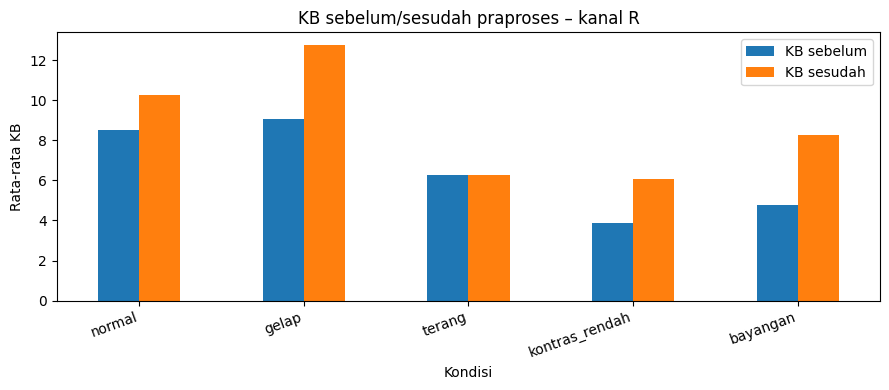

In [3]:
baris_integrasi = []
for _, d in label[label["kelas"] != "sehat"].iterrows():
    img = baca(CITRA / d.nama_file)
    md0 = baca(MASK_DAUN / d.nama_file, gray=True)
    mb0 = baca(MASK_BERCAK / d.nama_file, gray=True)
    out = praproses(img, PARAM_FINAL)
    ukuran = (out.shape[1], out.shape[0])
    md_out = cv2.resize(md0, ukuran, interpolation=cv2.INTER_NEAREST)
    mb_out = cv2.resize(mb0, ukuran, interpolation=cv2.INTER_NEAREST)
    sebelum = kontras_bercak(img[:, :, KANAL_INDEX], md0, mb0)
    sesudah = kontras_bercak(out[:, :, KANAL_INDEX], md_out, mb_out)
    baris_integrasi.append([d.kondisi_cahaya, d.kelas, d.nama_file, sebelum, sesudah])

evaluasi = pd.DataFrame(baris_integrasi, columns=["Kondisi", "Kelas", "Citra", "KB sebelum", "KB sesudah"])
tabel_12 = evaluasi.groupby("Kondisi")[["KB sebelum", "KB sesudah"]].mean().reindex(["normal", "gelap", "terang", "kontras_rendah", "bayangan"]).round(2)
tabel_12["Perubahan (%)"] = ((tabel_12["KB sesudah"] - tabel_12["KB sebelum"]) / tabel_12["KB sebelum"].replace(0, np.nan) * 100).round(2)
display(tabel_12)
evaluasi.to_csv(HASIL / "b5_evaluasi_40_citra.csv", index=False)
tabel_12.to_csv(HASIL / "b5_tabel_12_evaluasi_kb.csv")
ax = tabel_12[["KB sebelum", "KB sesudah"]].plot(kind="bar", figsize=(9, 4))
ax.set_ylabel("Rata-rata KB"); ax.set_title(f"KB sebelum/sesudah praproses – kanal {KANAL_NAMA}")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.savefig(HASIL / "b5_grafik_kb.png", dpi=150); plt.show()

## 5.4 Uji bercak palsu pada 20 citra kelas sehat

Hitung simpangan baku kanal terpilih di area daun dari `mask_daun`, sebelum dan sesudah praproses. Tampilkan satu citra untuk setiap kondisi cahaya.

,Std sebelum,Std sesudah
Kondisi,,
normal,11.46,9.43
gelap,9.83,7.78
terang,12.28,10.96
kontras_rendah,11.17,8.70
bayangan,14.49,10.15


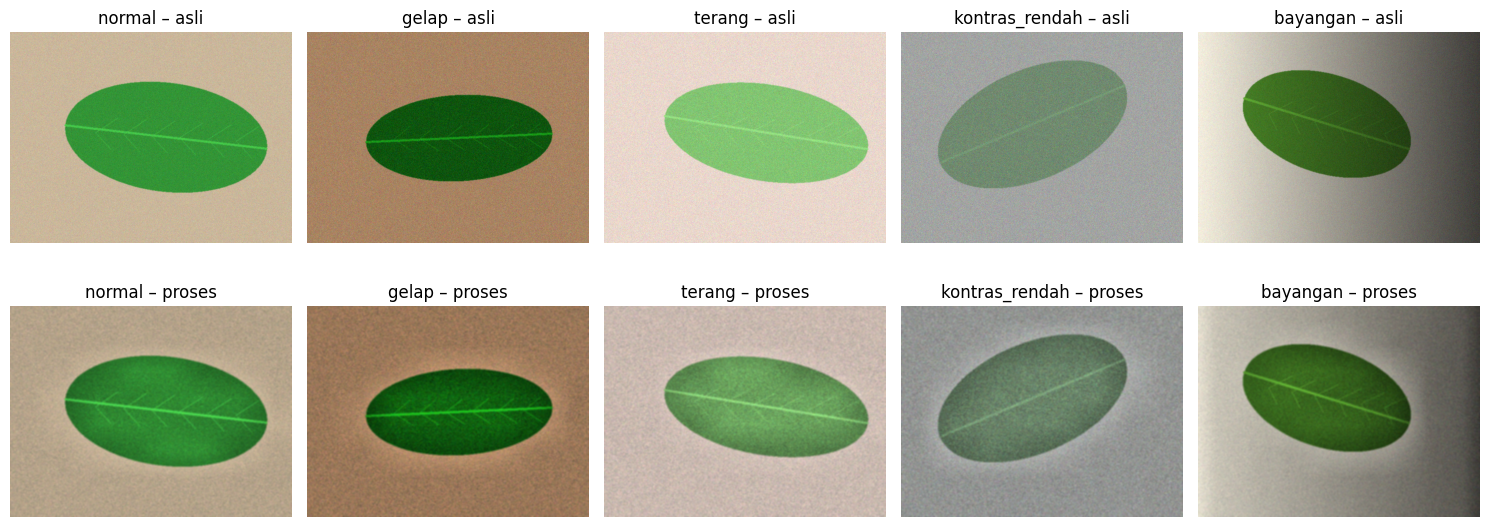

In [4]:
baris_sehat = []
panel_sehat = []
for _, d in label[label["kelas"] == "sehat"].iterrows():
    img = baca(CITRA / d.nama_file)
    md0 = baca(MASK_DAUN / d.nama_file, gray=True) > 0
    out = praproses(img, PARAM_FINAL)
    md_out = cv2.resize(md0.astype(np.uint8), (out.shape[1], out.shape[0]), interpolation=cv2.INTER_NEAREST) > 0
    sebelum = img[:, :, KANAL_INDEX][md0].std()
    sesudah = out[:, :, KANAL_INDEX][md_out].std()
    baris_sehat.append([d.nama_file, d.kondisi_cahaya, sebelum, sesudah])
    if d.kondisi_cahaya in ["normal", "gelap", "terang", "kontras_rendah", "bayangan"] and not any(x[0] == d.kondisi_cahaya for x in panel_sehat):
        panel_sehat.append((d.kondisi_cahaya, img, out, d.nama_file))

tabel_sehat = pd.DataFrame(baris_sehat, columns=["Citra", "Kondisi", "Std sebelum", "Std sesudah"])
ringkasan_sehat = tabel_sehat.groupby("Kondisi")[["Std sebelum", "Std sesudah"]].mean().reindex(["normal", "gelap", "terang", "kontras_rendah", "bayangan"]).round(2)
display(ringkasan_sehat)
tabel_sehat.to_csv(HASIL / "b5_uji_kelas_sehat_detail.csv", index=False)
ringkasan_sehat.to_csv(HASIL / "b5_uji_kelas_sehat.csv")

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, (kondisi, asli, sesudah, nama_file) in enumerate(panel_sehat):
    axes[0, i].imshow(cv2.cvtColor(asli, cv2.COLOR_BGR2RGB)); axes[0, i].set_title(f"{kondisi} – asli"); axes[0, i].axis("off")
    axes[1, i].imshow(cv2.cvtColor(sesudah, cv2.COLOR_BGR2RGB)); axes[1, i].set_title(f"{kondisi} – proses"); axes[1, i].axis("off")
plt.tight_layout(); plt.savefig(HASIL / "b5_panel_kelas_sehat.png", dpi=150); plt.show()

## 5.5 Justifikasi parameter final

Lengkapi alasan berdasarkan tabel dan gambar Anda. Tabel awal di bawah hanya contoh struktur dan perlu disesuaikan dengan bukti hasil pengujian.

In [5]:
justifikasi = pd.DataFrame([
    ["Ubah ukuran", f"lebar={PARAM_FINAL['lebar']} px", "Menjaga ukuran kerja sesuai kebutuhan pemrosesan; rujuk hasil akuisisi B2.", "Resize terlalu kecil dapat menghilangkan bercak kecil."],
    ["Koreksi gamma", f"gamma={PARAM_FINAL['gamma']}", "Nilai 1.0 berarti tidak mengubah intensitas; aktifkan hanya bila diagnosis B3 mendukung.", "Gamma yang salah dapat membuat citra terlalu gelap/terang."],
    ["CLAHE kanal V", f"clip={PARAM_FINAL['clahe_clip']}, tile={PARAM_FINAL['clahe_tile']}", "Mengubah kontras kanal kecerahan; periksa KB dan tampilan di B3.", "Penguatan berlebih dapat memperjelas derau atau memunculkan bercak palsu."],
    ["Redam derau", f"{PARAM_FINAL['penapis']} / kernel {PARAM_FINAL['kernel']}", "Titik awal dari perbandingan PSNR, waktu, dan KB di B4.", "Kernel besar dapat menghapus detail bercak kecil."],
    ["Tajamkan", f"tajam_k={PARAM_FINAL['tajam_k']}", "Nilai 0 berarti penajaman tidak diterapkan; aktifkan bila bukti mendukung.", "Penajaman berlebih dapat memperkuat derau dan tepi palsu."],
], columns=["Langkah", "Parameter final", "Alasan dan bukti", "Risiko bila salah atur"])
display(justifikasi)
justifikasi.to_csv(HASIL / "b5_justifikasi_parameter.csv", index=False)
print("Berkas parameter:", (HASIL / "param_praproses.json").read_text(encoding="utf-8"))

,Langkah,Parameter final,Alasan dan bukti,Risiko bila salah atur
0,Ubah ukuran,lebar=640 px,Menjaga ukuran kerja sesuai kebutuhan pemroses...,Resize terlalu kecil dapat menghilangkan berca...
1,Koreksi gamma,gamma=1.0,Nilai 1.0 berarti tidak mengubah intensitas; a...,Gamma yang salah dapat membuat citra terlalu g...
2,CLAHE kanal V,"clip=2.0, tile=8",Mengubah kontras kanal kecerahan; periksa KB d...,Penguatan berlebih dapat memperjelas derau ata...
3,Redam derau,rerata / kernel 5,"Titik awal dari perbandingan PSNR, waktu, dan ...",Kernel besar dapat menghapus detail bercak kecil.
4,Tajamkan,tajam_k=0.0,Nilai 0 berarti penajaman tidak diterapkan; ak...,Penajaman berlebih dapat memperkuat derau dan ...


Berkas parameter: {
  "lebar": 640,
  "gamma": 1.0,
  "clahe_clip": 2.0,
  "clahe_tile": 8,
  "penapis": "rerata",
  "kernel": 5,
  "sigma": 1.0,
  "tajam_k": 0.0
}


## 5.6 Pertanyaan analisis P5

Jawab pada laporan dengan rujukan tabel/gambar: **P5.1** apakah KB naik pada semua kondisi; **P5.2** penyebab kondisi yang KB-nya turun dan kemungkinan perbaikan adaptif; **P5.3** apakah muncul bercak palsu/kenaikan variasi daun sehat; **P5.4** alasan parameter sama diterapkan pada data latih dan uji; **P5.5** penerapan dua nilai AIK (amanah, jujur, adil, peduli, profesional, tabligh).

**Bukti Bagian 5:** `src/praproses.py`, `hasil/param_praproses.json`, Tabel 12, Tabel 13, hasil uji 20 citra sehat, panel, dan diagram. Setelah semua notebook berhasil `Restart & Run All`, perbarui README, commit, dan beri tag `v0.1-praproses`.